# Task 2. Оценка умственной работоспособности по RGB-сигналам лица

**Задача.** По RGB-сигналам, снятым с лица (1 кадр/с, усреднение пикселей по области лица, сглаживание Савицкого–Голея), предсказать уровень умственной работоспособности (`AU`, обратная величина усталости) для каждой минуты.

**Что сделано в ноутбуке**
1. Загрузка и разведочный анализ данных (10 участников).
2. Предобработка: z-нормализация сигнала внутри участника.
3. Две постановки: **классификация** (высокая/низкая работоспособность, порог — медиана) и **регрессия** (непрерывный `AU`).
4. Признаки для ML: статистические, временные, частотные, межканальные.
5. **8 ML-моделей** и **5 DL-моделей** на **7 комбинациях каналов** (R, G, B, RG, RB, GB, RGB).
6. Валидация **Leave-One-Subject-Out** (тест всегда на человеке, которого модель не видела).
7. Сравнительный анализ, матрицы ошибок, анализ утечки данных, выводы.

## 0. Импорты и общие функции

In [1]:
import time, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
os.makedirs("results", exist_ok=True)
# True — переобучить все модели заново (~10 мин ML + ~1 ч DL на CPU);
# False — взять сохранённые результаты из results/, если они есть.
RECOMPUTE = False

In [2]:
import glob, re, warnings
import numpy as np, pandas as pd
from scipy import stats, signal

warnings.filterwarnings("ignore")
DATA_DIR = "data"  # папка с подпапками R/, G/, B/
CHANNELS = ["R", "G", "B"]
COMBOS = ["R", "G", "B", "RG", "RB", "GB", "RGB"]
TCOLS = [f"t{i}" for i in range(60)]


def load_data(data_dir=DATA_DIR):
    per_ch = {}
    for c in CHANNELS:
        parts = []
        for f in sorted(glob.glob(f"{data_dir}/{c}/{c}_chunks_*.csv")):
            d = pd.read_csv(f)
            d["subject"] = int(re.search(r"_(\d+)\.csv$", f).group(1))
            parts.append(d)
        per_ch[c] = pd.concat(parts, ignore_index=True)
    meta = per_ch["R"][["subject", "file", "AU"]].copy()
    for c in "GB":
        assert (per_ch[c]["file"].values == meta["file"].values).all()
    meta["session"] = meta["subject"].astype(str) + "_" + meta["file"].str.replace(r"_min\d+$", "", regex=True)
    meta["minute"] = meta["file"].str.extract(r"_min(\d+)$").astype(int)
    X = np.stack([per_ch[c][TCOLS].values for c in CHANNELS], axis=-1)  # (N, 60, 3)
    keep = meta["AU"].notna().values
    return X[keep], meta[keep].reset_index(drop=True)


def subject_zscore(X, subjects):
    """Z-нормализация каждого канала внутри участника (по всем его минутам)."""
    Xn = np.empty_like(X, dtype=float)
    for s in np.unique(subjects):
        m = subjects == s
        mu = X[m].mean(axis=(0, 1), keepdims=True)
        sd = X[m].std(axis=(0, 1), keepdims=True)
        Xn[m] = (X[m] - mu) / sd
    return Xn


def _channel_features(x):
    """x: (60,) сигнал одного канала за минуту, fs = 1 Гц."""
    f = {}
    f["mean"] = x.mean(); f["std"] = x.std(); f["min"] = x.min(); f["max"] = x.max()
    f["range"] = f["max"] - f["min"]; f["median"] = np.median(x)
    q25, q75 = np.percentile(x, [25, 75]); f["q25"] = q25; f["q75"] = q75; f["iqr"] = q75 - q25
    f["skew"] = stats.skew(x); f["kurt"] = stats.kurtosis(x)
    t = np.arange(len(x)); f["slope"] = np.polyfit(t, x, 1)[0]
    xc = x - x.mean(); den = (xc ** 2).sum() + 1e-12
    for lag in (1, 3, 5, 10):
        f[f"acf{lag}"] = (xc[:-lag] * xc[lag:]).sum() / den
    f["mean_cross"] = int(((xc[:-1] * xc[1:]) < 0).sum())
    dx = np.diff(x); f["diff_std"] = dx.std(); f["diff_absmean"] = np.abs(dx).mean()
    f["n_peaks"] = len(signal.find_peaks(x)[0])
    # частотные (Найквист = 0.5 Гц)
    freqs, pxx = signal.periodogram(signal.detrend(x), fs=1.0)
    freqs, pxx = freqs[1:], pxx[1:]
    tot = pxx.sum() + 1e-12; p = pxx / tot
    f["dom_freq"] = freqs[np.argmax(pxx)]
    f["spec_centroid"] = (freqs * p).sum()
    f["spec_entropy"] = -(p * np.log2(p + 1e-12)).sum() / np.log2(len(p))
    for lo, hi in [(0, 0.05), (0.05, 0.15), (0.15, 0.3), (0.3, 0.51)]:
        f[f"bp_{lo}-{hi}"] = pxx[(freqs > lo) & (freqs <= hi)].sum() / tot
    f["log_power"] = np.log(tot)
    return f


def extract_features(Xn):
    rows = []
    for w in Xn:
        r = {}
        for ci, c in enumerate(CHANNELS):
            for k, v in _channel_features(w[:, ci]).items():
                r[f"{c}_{k}"] = v
        for a, b in [("R", "G"), ("R", "B"), ("G", "B")]:
            ia, ib = CHANNELS.index(a), CHANNELS.index(b)
            r[f"{a}{b}_corr"] = np.corrcoef(w[:, ia], w[:, ib])[0, 1]
            r[f"{a}{b}_meandiff"] = w[:, ia].mean() - w[:, ib].mean()
        rows.append(r)
    return pd.DataFrame(rows).fillna(0.0)


def cols_for_combo(feat_cols, combo):
    out = []
    for c in feat_cols:
        pref = c.split("_")[0]
        if len(pref) == 1 and pref in combo:
            out.append(c)
        elif len(pref) == 2 and all(ch in combo for ch in pref):
            out.append(c)
    return out

## 1. Загрузка и разведочный анализ данных

In [3]:
X, meta = load_data()
print("Форма сигнала (минуты, отсчёты, каналы):", X.shape)
print("Участников:", meta.subject.nunique(), "| сессий:", meta.session.nunique(), "| минут:", len(meta))
summary = meta.groupby("subject").agg(minutes=("AU", "size"), sessions=("session", "nunique"),
                                      AU_mean=("AU", "mean"), AU_std=("AU", "std"), AU_min=("AU", "min"), AU_max=("AU", "max"))
summary.round(2)

Форма сигнала (минуты, отсчёты, каналы): (1055, 60, 3)
Участников: 10 | сессий: 211 | минут: 1055


,minutes,sessions,AU_mean,AU_std,AU_min,AU_max
subject,,,,,,
3,92,19,1.77,0.78,0.53,2.85
4,74,15,1.29,0.77,-0.41,2.53
5,120,24,1.95,0.69,-0.25,2.87
6,117,23,1.85,0.65,0.45,2.81
7,125,25,1.28,0.69,0.18,2.70
8,95,19,2.03,0.74,0.65,3.13
9,125,25,1.61,0.89,-0.32,2.83
10,135,27,2.20,0.74,0.31,2.99
11,87,17,0.13,0.29,-0.30,0.76


Каждая строка исходных CSV — одна минута записи: 60 отсчётов (`t0…t59`, 1 Гц), имя сессии с номером минуты (`file`) и оценка `AU`. Файлы R, G, B выровнены построчно. У одной сессии (участник 6, `23-01-31-rings-afternoon`) нет оценки — эти 5 минут удалены (1060 → 1055).

Уникальных значений AU внутри сессии: 1


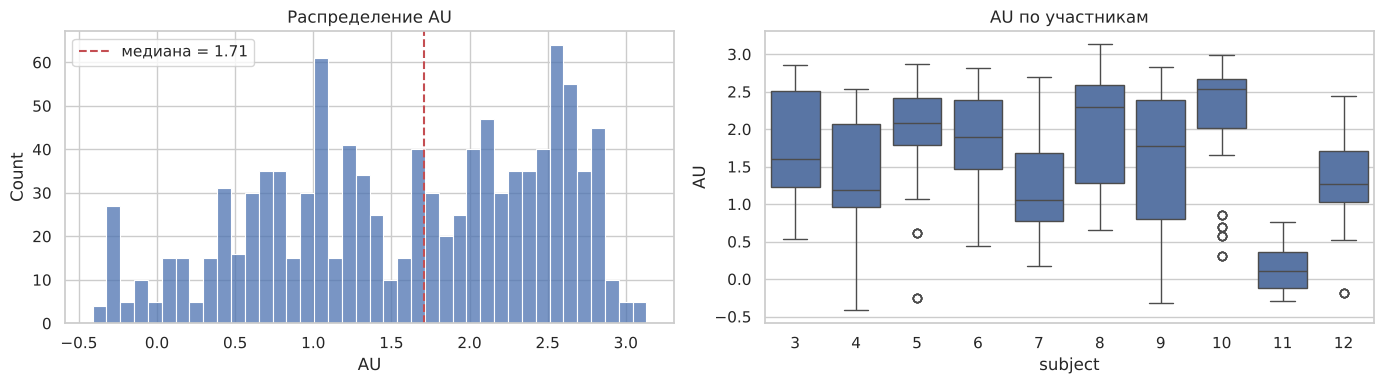

In [4]:
print("Уникальных значений AU внутри сессии:", meta.groupby("session").AU.nunique().max())
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(meta.AU, bins=40, ax=ax[0]); ax[0].axvline(meta.AU.median(), c="r", ls="--", label=f"медиана = {meta.AU.median():.2f}")
ax[0].set_title("Распределение AU"); ax[0].legend()
sns.boxplot(data=meta, x="subject", y="AU", ax=ax[1]); ax[1].set_title("AU по участникам")
plt.tight_layout(); plt.show()

**Важные наблюдения**
- Оценка `AU` ставится **на сессию** (≈5 минут подряд), а не на каждую минуту: внутри сессии значение одинаковое. Независимых меток не 1055, а **211**.
- Участники сильно различаются по уровню `AU`. Особенно выделяется участник 11: почти все значения около 0, все его минуты попадают в класс «низкая работоспособность».
- Отсюда следует, что случайное перемешивание минут недопустимо: минуты одной сессии окажутся и в train, и в test (см. раздел 8).

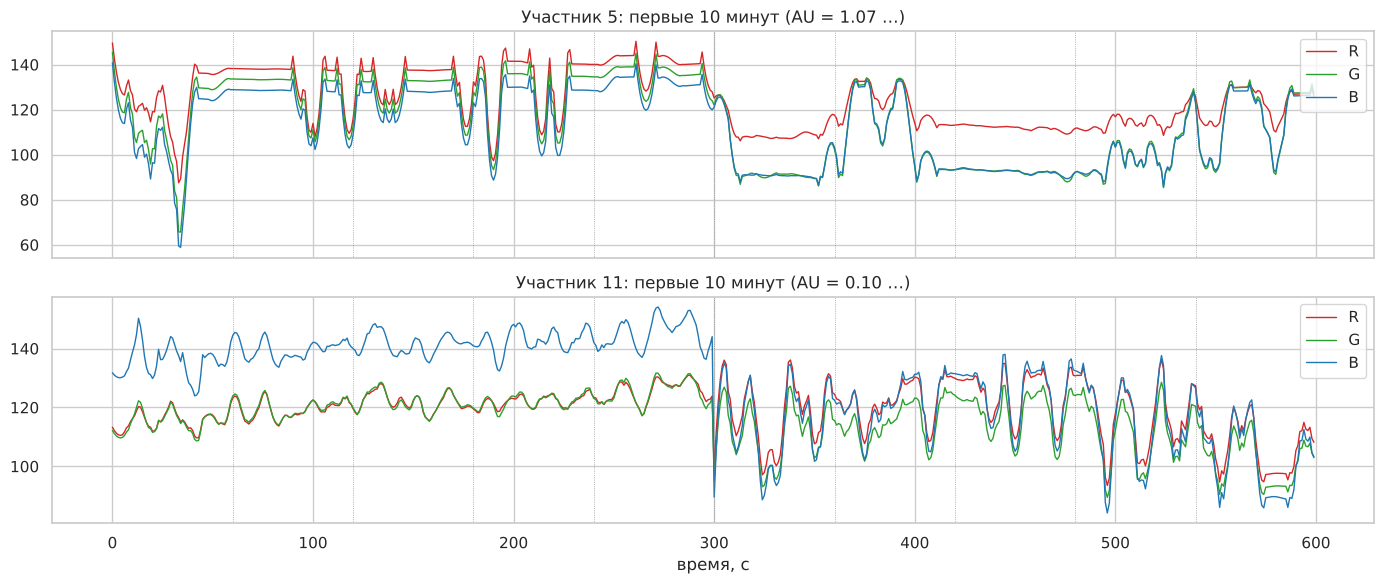

Средняя автокорреляция lag-1 канала G: 0.93 — сигнал уже сглажен (Савицкий–Голей применён на этапе пайплайна).


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, s in zip(axes, [5, 11]):
    m = np.where(meta.subject == s)[0][:10]
    for ci, c in enumerate(CHANNELS):
        ax.plot(X[m, :, ci].reshape(-1), c={"R": "tab:red", "G": "tab:green", "B": "tab:blue"}[c], label=c, lw=1)
    for k in range(1, 10): ax.axvline(60 * k, c="gray", lw=0.5, ls=":")
    ax.set_title(f"Участник {s}: первые 10 минут (AU = {meta.AU.values[m[0]]:.2f} …)"); ax.legend(loc="upper right")
axes[-1].set_xlabel("время, с"); plt.tight_layout(); plt.show()
lag1 = np.mean([np.corrcoef(w[:-1, 1], w[1:, 1])[0, 1] for w in X])
print(f"Средняя автокорреляция lag-1 канала G: {lag1:.2f} — сигнал уже сглажен (Савицкий–Голей применён на этапе пайплайна).")

## 2. Предобработка

- **Сглаживание** повторно не применяем: сигнал уже прошёл фильтр Савицкого–Голея (автокорреляция lag-1 ≈ 0,93).
- **Z-нормализация внутри участника** по каждому каналу. Абсолютный уровень R/G/B зависит от тона кожи, освещения и камеры; без нормализации модель выучит «кто это», а не «насколько он устал». Нормализация не использует метки, поэтому утечки нет.
- Частота 1 Гц: предел Найквиста 0,5 Гц. Пульс (1–2 Гц) из такого сигнала извлечь **нельзя**, доступны только медленные колебания (дыхание, движения, освещение).

In [6]:
Xn = subject_zscore(X, meta.subject.values).astype(np.float32)
groups = meta.subject.values
y_reg = meta.AU.values
THR = np.median(y_reg)
y_clf = (y_reg > THR).astype(int)
print(f"Порог классификации (медиана AU) = {THR:.3f}; доля класса 1 = {y_clf.mean():.3f}")
display(pd.crosstab(meta.subject, y_clf, colnames=["класс"]))

Порог классификации (медиана AU) = 1.707; доля класса 1 = 0.499


класс,0,1
subject,,
3,47,45
4,54,20
5,25,95
6,41,76
7,95,30
8,30,65
9,60,65
10,30,105
11,87,0


## 3. Признаки для ML

Для каждого канала и каждой минуты (60 отсчётов) считается 30 признаков:

| Группа | Признаки |
|---|---|
| Статистические | mean, std, min, max, range, median, q25, q75, IQR, skewness, kurtosis |
| Временные | наклон тренда, автокорреляция (lag 1/3/5/10), число пересечений среднего, std и средний модуль первой разности, число пиков |
| Частотные | доминирующая частота, спектральный центроид, спектральная энтропия, доли мощности в полосах 0–0,05 / 0,05–0,15 / 0,15–0,3 / 0,3–0,5 Гц, log-мощность |
| Межканальные (для 2–3 каналов) | корреляция пар каналов, разность средних |

Итого 3 × 28 + 3 × 2 = 90 признаков для RGB, 28 для одного канала, 58 для пары.

In [7]:
F = extract_features(Xn)
print(F.shape); F.iloc[:3, :12].round(3)

(1055, 90)


,R_mean,R_std,R_min,R_max,R_range,R_median,R_q25,R_q75,R_iqr,R_skew,R_kurt,R_slope
0,2.272,0.155,1.921,2.611,0.690,2.292,2.169,2.366,0.197,-0.419,-0.177,-0.006
1,1.889,0.148,1.595,2.259,0.665,1.883,1.778,1.961,0.183,0.557,-0.008,-0.002
2,1.787,0.177,1.302,2.238,0.936,1.834,1.670,1.892,0.222,-0.442,0.914,-0.001


In [8]:
# Насколько признаки вообще связаны с AU? Корреляция Спирмена (по всем минутам и внутри участников)
from scipy.stats import spearmanr
corr_all = F.apply(lambda c: spearmanr(c, y_reg)[0])
within = pd.DataFrame({s: F[groups == s].apply(lambda c: spearmanr(c, y_reg[groups == s])[0]) for s in np.unique(groups)})
fc = pd.DataFrame({"rho_all": corr_all, "rho_within_mean": within.mean(1), "same_sign_subjects": (np.sign(within).eq(np.sign(within.mean(1)), axis=0)).sum(1)})
fc.reindex(fc.rho_within_mean.abs().sort_values(ascending=False).index).head(12).round(3)

,rho_all,rho_within_mean,same_sign_subjects
B_iqr,-0.106,-0.120,8
G_iqr,-0.043,-0.106,8
R_q25,0.027,0.099,8
R_iqr,-0.028,-0.098,8
R_mean,0.031,0.093,6
R_median,0.014,0.089,6
R_min,0.048,0.087,7
G_q25,0.034,0.087,7
B_acf10,0.103,0.087,8
R_max,0.046,0.086,5


Даже самые «сильные» признаки связаны с `AU` очень слабо (|ρ| < 0,1), и направление связи у разных участников разное. Это первый сигнал, что задача на этих данных очень трудная.

## 4. Схема валидации

**Leave-One-Subject-Out (LOSO):** 10 фолдов, в каждом один участник целиком уходит в тест, модель обучается на остальных девяти. Предсказания всех фолдов собираются в один вектор (out-of-fold), по нему считаются метрики.

Это самая честная схема для вопроса «будет ли модель работать на новом человеке». Минуты одной сессии и одного человека никогда не попадают одновременно в train и test.

**Метрики:** классификация — Accuracy, Precision, Recall, F1, ROC-AUC, матрица ошибок; регрессия — RMSE, MAE, R², корреляция Пирсона.
**Бейзлайны:** мажоритарный класс (Accuracy ≈ 0,50) и предсказание среднего AU обучающей части (RMSE ≈ 0,92).

In [9]:
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, KFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, mean_squared_error, mean_absolute_error, r2_score)
logo = LeaveOneGroupOut()

def clf_metrics(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    return dict(Accuracy=accuracy_score(y, yh), Precision=precision_score(y, yh, zero_division=0),
                Recall=recall_score(y, yh), F1=f1_score(y, yh), ROC_AUC=roc_auc_score(y, p))

def reg_metrics(y, p):
    return dict(RMSE=mean_squared_error(y, p) ** 0.5, MAE=mean_absolute_error(y, p), R2=r2_score(y, p), Pearson=np.corrcoef(y, p)[0, 1])

# Бейзлайны
base_mean = np.zeros(len(y_reg)); base_prior = np.zeros(len(y_reg))
for tr, te in logo.split(F, y_reg, groups):
    base_mean[te] = y_reg[tr].mean(); base_prior[te] = y_clf[tr].mean()
baselines = pd.DataFrame([
    dict(task="clf", model="Majority class", Accuracy=max(y_clf.mean(), 1 - y_clf.mean()), F1=np.nan, ROC_AUC=0.5),
    dict(task="reg", model="Mean of train", **reg_metrics(y_reg, base_mean))])
baselines.round(3)

,task,model,Accuracy,F1,ROC_AUC,RMSE,MAE,R2,Pearson
0,clf,Majority class,0.501,NaN,0.5,NaN,NaN,NaN,NaN
1,reg,Mean of train,NaN,NaN,NaN,0.922,0.802,-0.08,-0.593


## 5. ML-модели

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, ExtraTreesClassifier, ExtraTreesRegressor
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from catboost import CatBoostClassifier, CatBoostRegressor

CLF = {
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)),
    "SVM": lambda: make_pipeline(StandardScaler(), SVC(C=1.0, probability=True, random_state=SEED)),
    "kNN": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25)),
    "RandomForest": lambda: RandomForestClassifier(200, min_samples_leaf=5, n_jobs=2, random_state=SEED),
    "ExtraTrees": lambda: ExtraTreesClassifier(200, min_samples_leaf=5, n_jobs=2, random_state=SEED),
    "XGBoost": lambda: XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, n_jobs=2, random_state=SEED, verbosity=0),
    "LightGBM": lambda: LGBMClassifier(n_estimators=300, num_leaves=15, learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, min_child_samples=20, n_jobs=2, random_state=SEED, verbose=-1),
    "CatBoost": lambda: CatBoostClassifier(iterations=300, depth=4, learning_rate=0.05, random_seed=SEED, verbose=0, thread_count=2),
}
REG = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "SVR": lambda: make_pipeline(StandardScaler(), SVR(C=1.0)),
    "kNN": lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=25)),
    "RandomForest": lambda: RandomForestRegressor(200, min_samples_leaf=5, n_jobs=2, random_state=SEED),
    "ExtraTrees": lambda: ExtraTreesRegressor(200, min_samples_leaf=5, n_jobs=2, random_state=SEED),
    "XGBoost": lambda: XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, n_jobs=2, random_state=SEED, verbosity=0),
    "LightGBM": lambda: LGBMRegressor(n_estimators=300, num_leaves=15, learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.7, min_child_samples=20, n_jobs=2, random_state=SEED, verbose=-1),
    "CatBoost": lambda: CatBoostRegressor(iterations=300, depth=4, learning_rate=0.05, random_seed=SEED, verbose=0, thread_count=2),
}

def oof_predict(make, Xm, y, proba):
    pred = np.zeros(len(y))
    for tr, te in logo.split(Xm, y, groups):
        m = make(); m.fit(Xm[tr], y[tr])
        pred[te] = m.predict_proba(Xm[te])[:, 1] if proba else m.predict(Xm[te])
    return pred

In [11]:
if RECOMPUTE or not os.path.exists("results/ml_results.csv"):
    rows, ml_preds = [], {}
    t0 = time.time()
    for combo in COMBOS:
        cols = cols_for_combo(F.columns, combo); Xm = F[cols].values
        for name, mk in CLF.items():
            p = oof_predict(mk, Xm, y_clf, True); ml_preds[("clf", name, combo)] = p
            rows.append(dict(task="clf", family="ML", model=name, combo=combo, n_feat=len(cols), **clf_metrics(y_clf, p)))
        for name, mk in REG.items():
            p = oof_predict(mk, Xm, y_reg, False); ml_preds[("reg", name, combo)] = p
            rows.append(dict(task="reg", family="ML", model=name, combo=combo, n_feat=len(cols), **reg_metrics(y_reg, p)))
        print(combo, f"{time.time() - t0:.0f} c")
    ml_res = pd.DataFrame(rows); ml_res.to_csv("results/ml_results.csv", index=False); pd.to_pickle(ml_preds, "results/ml_preds.pkl")
else:
    ml_res = pd.read_csv("results/ml_results.csv"); ml_preds = pd.read_pickle("results/ml_preds.pkl")
print(ml_res.shape)

(112, 14)


## 6. DL-модели

Вход — сам временной ряд минуты: тензор 60 × k (k = число каналов), после z-нормализации внутри участника. Модели намеренно маленькие (данных ~950 минут на обучение):

- **1D-CNN** — 3 свёрточных блока + global average pooling;
- **LSTM** (32 нейрона) и **GRU** (32);
- **CNN+LSTM** — свёртки с пулингом сжимают ряд до 15 шагов, затем LSTM;
- **Transformer** — патчи по 4 с (15 токенов), 1 слой энкодера, 4 головы.

Обучение: AdamW (lr = 2e-3, weight decay = 1e-2), 25 эпох, batch 64, аугментация гауссовым шумом; BCE-loss для классификации, MSE на стандартизованной цели для регрессии. Та же валидация LOSO.

In [12]:
import torch, torch.nn as nn
torch.set_num_threads(2)

class CNN1D(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.net = nn.Sequential(
            nn.Conv1d(c, 16, 5, padding=2), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(16, 32, 5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(), nn.AdaptiveAvgPool1d(1),
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(s, x): return s.net(x.transpose(1, 2)).squeeze(-1)


class LSTMNet(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.rnn = nn.LSTM(c, 32, num_layers=1, batch_first=True)
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(s, x):
        _, (h, _) = s.rnn(x); return s.head(h[-1]).squeeze(-1)


class GRUNet(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.rnn = nn.GRU(c, 32, batch_first=True)
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(s, x):
        _, h = s.rnn(x); return s.head(h[-1]).squeeze(-1)


class CNNLSTM(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.conv = nn.Sequential(nn.Conv1d(c, 16, 5, padding=2), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
                               nn.Conv1d(16, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2))
        s.rnn = nn.LSTM(32, 32, batch_first=True)
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(s, x):
        z = s.conv(x.transpose(1, 2)).transpose(1, 2)
        _, (h, _) = s.rnn(z); return s.head(h[-1]).squeeze(-1)


class TinyTransformer(nn.Module):
    def __init__(s, c, d=32):
        super().__init__()
        s.proj = nn.Conv1d(c, d, kernel_size=4, stride=4)  # патчи по 4 с -> 15 токенов
        s.pos = nn.Parameter(torch.randn(1, 15, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=64, dropout=0.2, batch_first=True)
        s.enc = nn.TransformerEncoder(layer, num_layers=1)
        s.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(d, 1))
    def forward(s, x):
        z = s.enc(s.proj(x.transpose(1, 2)).transpose(1, 2) + s.pos); return s.head(z.mean(1)).squeeze(-1)


MODELS = {"1D-CNN": CNN1D, "LSTM": LSTMNet, "GRU": GRUNet, "CNN+LSTM": CNNLSTM, "Transformer": TinyTransformer}
EPOCHS, BS, LR = 25, 64, 2e-3


def fit_predict(Model, Xtr, ytr, Xte, task, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    m = Model(Xtr.shape[-1])
    opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=1e-2)
    if task == "reg":
        mu, sd = ytr.mean(), ytr.std(); yt = (ytr - mu) / sd; lossf = nn.MSELoss()
    else:
        yt = ytr.astype(np.float32); lossf = nn.BCEWithLogitsLoss()
    Xt = torch.tensor(Xtr); Yt = torch.tensor(yt, dtype=torch.float32)
    n = len(Xt)
    for ep in range(EPOCHS):
        m.train(); perm = torch.randperm(n)
        for i in range(0, n, BS):
            idx = perm[i:i + BS]
            xb = Xt[idx] + 0.05 * torch.randn_like(Xt[idx])  # лёгкая аугментация шумом
            opt.zero_grad(); loss = lossf(m(xb), Yt[idx]); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        out = m(torch.tensor(Xte)).numpy()
    return torch.sigmoid(torch.tensor(out)).numpy() if task == "clf" else out * sd + mu

In [13]:
if RECOMPUTE or not os.path.exists("results/dl_results.csv"):
    rows, dl_preds = [], {}
    t0 = time.time()
    for task in ["clf", "reg"]:
        y = y_clf if task == "clf" else y_reg
        for combo in COMBOS:
            Xc = Xn[:, :, [CHANNELS.index(c) for c in combo]]
            for name, M in MODELS.items():
                p = np.zeros(len(y))
                for tr, te in logo.split(Xc, y, groups):
                    p[te] = fit_predict(M, Xc[tr], y[tr], Xc[te], task)
                dl_preds[(task, name, combo)] = p
                r = clf_metrics(y, p) if task == "clf" else reg_metrics(y, p)
                rows.append(dict(task=task, family="DL", model=name, combo=combo, n_feat=len(combo) * 60, **r))
            print(task, combo, f"{time.time() - t0:.0f} c")
    dl_res = pd.DataFrame(rows); dl_res.to_csv("results/dl_results.csv", index=False); pd.to_pickle(dl_preds, "results/dl_preds.pkl")
else:
    dl_res = pd.read_csv("results/dl_results.csv"); dl_preds = pd.read_pickle("results/dl_preds.pkl")
print(dl_res.shape)

(70, 14)


## 7. Сравнительный анализ

In [14]:
res = pd.concat([ml_res, dl_res], ignore_index=True)
preds = {**ml_preds, **dl_preds}
clf_res = res[res.task == "clf"].drop(columns=["RMSE", "MAE", "R2", "Pearson"], errors="ignore")
reg_res = res[res.task == "reg"].drop(columns=["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"], errors="ignore")
print("Классификация — топ-10 по F1 (LOSO):")
display(clf_res.sort_values("F1", ascending=False).head(10).round(3))
print("Регрессия — топ-10 по RMSE (LOSO):")
display(reg_res.sort_values("RMSE").head(10).round(3))

Классификация — топ-10 по F1 (LOSO):


,task,family,model,combo,n_feat,Accuracy,Precision,Recall,F1,ROC_AUC
137,clf,DL,1D-CNN,GB,120,0.467,0.470,0.544,0.504,0.459
145,clf,DL,CNN+LSTM,RGB,180,0.477,0.477,0.521,0.498,0.450
140,clf,DL,CNN+LSTM,GB,120,0.473,0.474,0.519,0.495,0.454
80,clf,ML,LogReg,GB,58,0.500,0.499,0.489,0.494,0.506
83,clf,ML,RandomForest,GB,58,0.482,0.481,0.490,0.486,0.447
38,clf,ML,LightGBM,B,28,0.482,0.481,0.487,0.484,0.449
87,clf,ML,CatBoost,GB,58,0.472,0.472,0.494,0.483,0.448
141,clf,DL,Transformer,GB,120,0.444,0.450,0.521,0.483,0.416
85,clf,ML,XGBoost,GB,58,0.477,0.476,0.487,0.481,0.452
22,clf,ML,LightGBM,G,28,0.476,0.474,0.473,0.474,0.448


Регрессия — топ-10 по RMSE (LOSO):


,task,family,model,combo,n_feat,RMSE,MAE,R2,Pearson
172,reg,DL,1D-CNN,GB,120,0.907,0.769,-0.044,0.125
173,reg,DL,LSTM,GB,120,0.926,0.799,-0.087,-0.245
154,reg,DL,GRU,G,60,0.928,0.808,-0.093,-0.251
174,reg,DL,GRU,GB,120,0.930,0.806,-0.098,-0.242
159,reg,DL,GRU,B,60,0.931,0.813,-0.099,-0.366
153,reg,DL,LSTM,G,60,0.931,0.811,-0.100,-0.291
148,reg,DL,LSTM,R,60,0.932,0.807,-0.102,-0.320
149,reg,DL,GRU,R,60,0.932,0.809,-0.103,-0.305
88,reg,ML,Ridge,GB,58,0.933,0.803,-0.104,0.021
158,reg,DL,LSTM,B,60,0.934,0.812,-0.107,-0.453


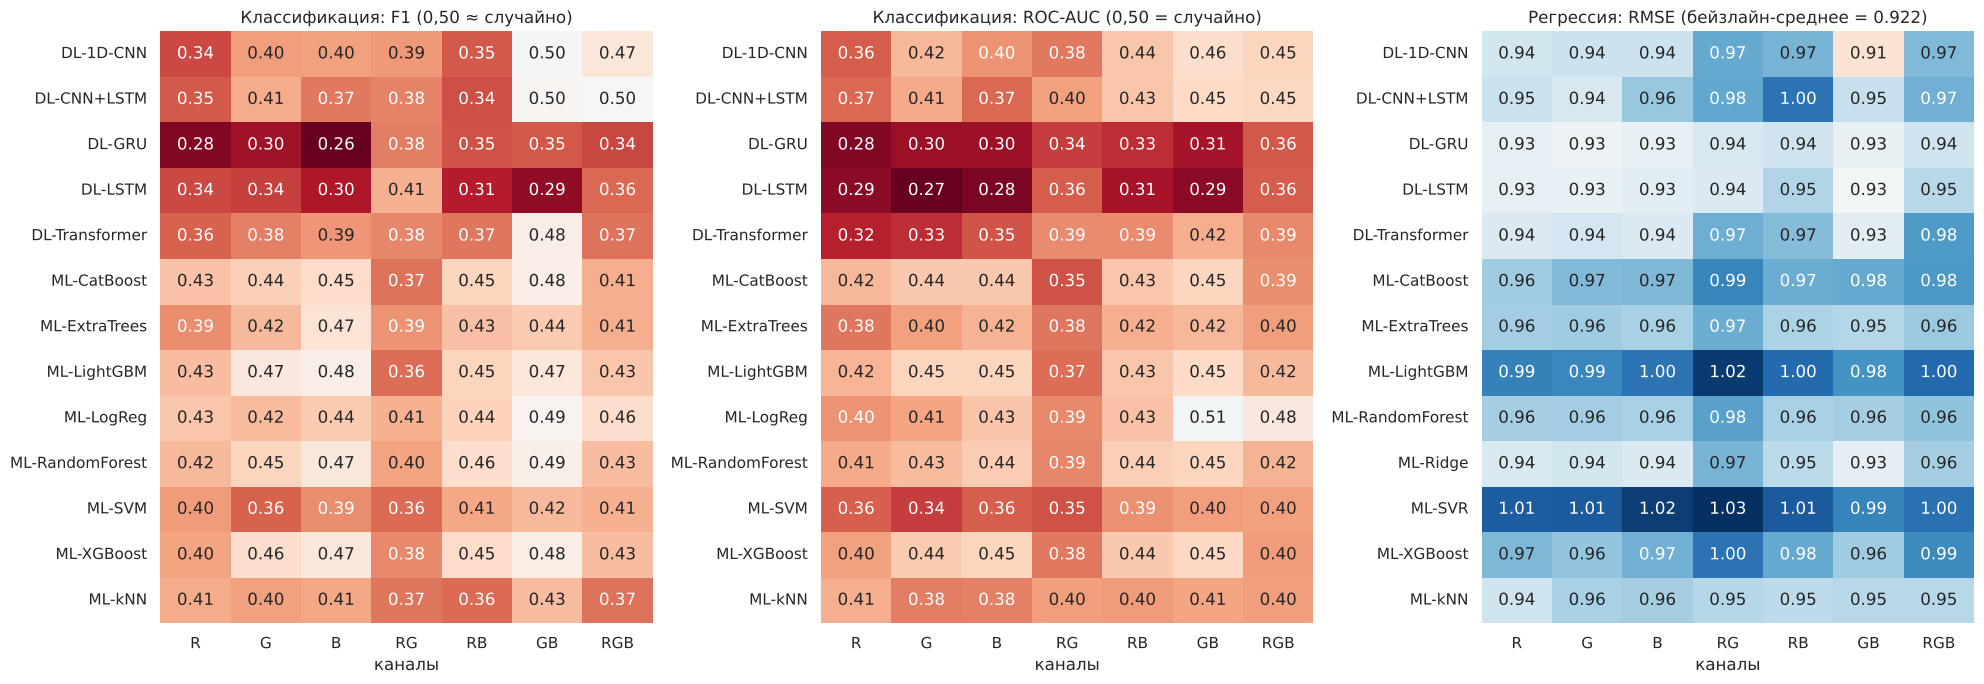

In [15]:
def heat(df, metric, title, ax, cmap, center):
    t = df.pivot_table(index=["family", "model"], columns="combo", values=metric)[COMBOS]
    sns.heatmap(t, annot=True, fmt=".2f", cmap=cmap, center=center, ax=ax, cbar=False)
    ax.set_title(title); ax.set_ylabel(""); ax.set_xlabel("каналы")

fig, ax = plt.subplots(1, 3, figsize=(20, 7))
heat(clf_res, "F1", "Классификация: F1 (0,50 ≈ случайно)", ax[0], "RdBu", 0.5)
heat(clf_res, "ROC_AUC", "Классификация: ROC-AUC (0,50 = случайно)", ax[1], "RdBu", 0.5)
heat(reg_res, "RMSE", f"Регрессия: RMSE (бейзлайн-среднее = {baselines.RMSE.iloc[1]:.3f})", ax[2], "RdBu", baselines.RMSE.iloc[1])
plt.tight_layout(); plt.show()

In [16]:
# Влияние каналов: среднее и лучшее значение по всем моделям
by_combo = pd.concat([
    clf_res.groupby("combo")[["F1", "ROC_AUC"]].agg(["mean", "max"]),
    reg_res.groupby("combo")[["RMSE"]].agg(["mean", "min"])], axis=1).loc[COMBOS]
display(by_combo.round(3))
# ML против DL
fam = pd.concat([clf_res.groupby("family")[["Accuracy", "F1", "ROC_AUC"]].agg(["mean", "max"]),
                 reg_res.groupby("family")[["RMSE", "MAE"]].agg(["mean", "min"])], axis=1)
display(fam.round(3))

F1        ROC_AUC          RMSE       
        mean    max    mean    max   mean    min
combo                                           
R      0.383  0.432   0.371  0.423  0.955  0.932
G      0.403  0.474   0.386  0.448  0.956  0.928
B      0.409  0.484   0.390  0.449  0.960  0.931
RG     0.386  0.414   0.375  0.405  0.978  0.938
RB     0.398  0.455   0.407  0.442  0.970  0.945
GB     0.448  0.504   0.420  0.506  0.950  0.907
RGB    0.415  0.498   0.409  0.476  0.971  0.944

Accuracy            F1        ROC_AUC          RMSE           MAE       
           mean    max   mean    max    mean    max   mean    min   mean    min
family                                                                         
DL        0.393  0.477  0.373  0.504   0.364  0.459  0.948  0.907  0.816  0.769
ML        0.442  0.500  0.426  0.494   0.413  0.506  0.972  0.933  0.836  0.803

### 7.1. Метрики внутри участника

Метрики выше считаются по объединённым out-of-fold предсказаниям всех 10 фолдов. У такой схемы есть систематический сдвиг **ниже** 0,5. Когда из обучения убирают участника с преимущественно высоким AU (например, 10), в обучающей выборке становится больше «низких», и модель смещает предсказания вниз именно для этого участника. Для участника 11 (только «низкие») всё наоборот. В итоге средний уровень предсказаний по участникам **антикоррелирует** с их истинным средним, и объединённый ROC-AUC опускается ниже 0,5 даже у модели без всякой информации.

Чтобы отделить этот эффект, считаем метрики **внутри каждого тестового участника** и усредняем: ROC-AUC (участник 11 исключён — у него один класс) и корреляцию Пирсона для регрессии. Вопрос здесь такой: различает ли модель более и менее «усталые» сессии одного человека?

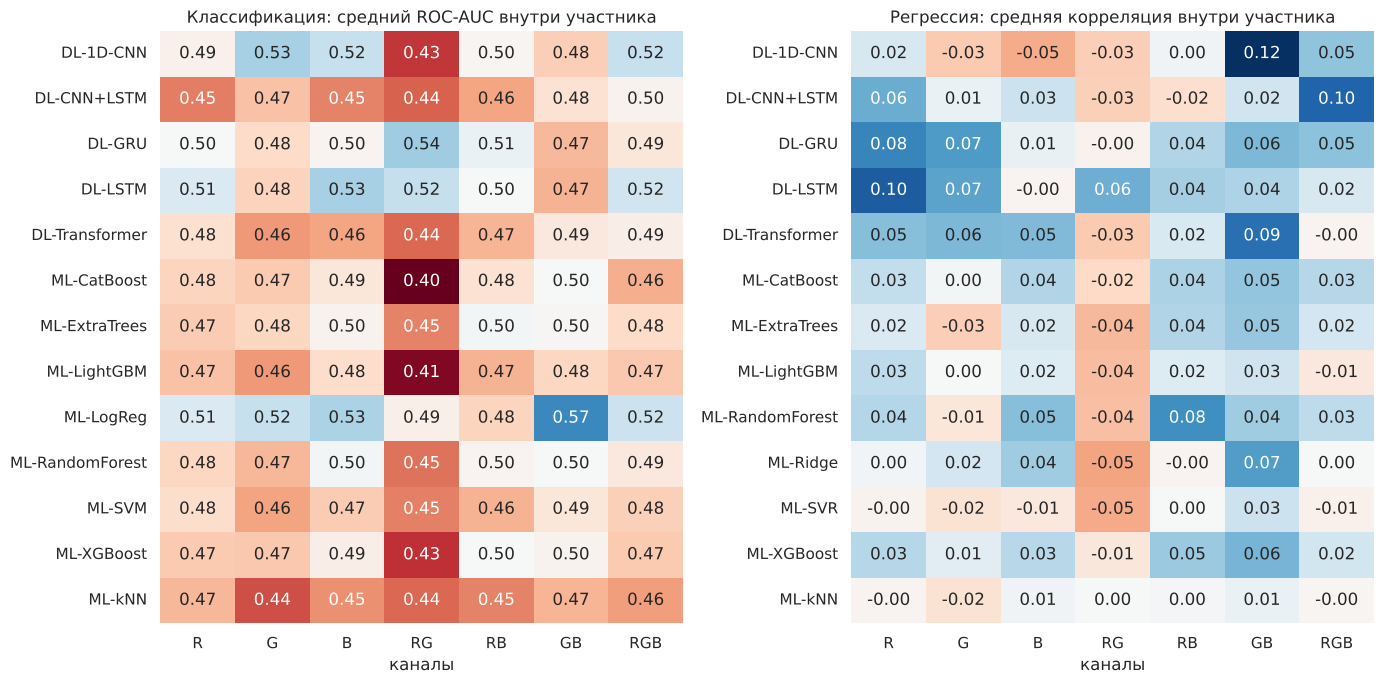

Лучшие по AUC внутри участника:


,family,model,combo,F1,ROC_AUC,AUC_within
80,ML,LogReg,GB,0.494,0.506,0.565
129,DL,GRU,RG,0.377,0.339,0.536
123,DL,LSTM,B,0.305,0.279,0.533
117,DL,1D-CNN,G,0.400,0.422,0.533
32,ML,LogReg,B,0.436,0.433,0.532


In [17]:
subj_list = np.unique(groups)
def within_auc(p):
    v = [roc_auc_score(y_clf[groups == s], p[groups == s]) for s in subj_list if y_clf[groups == s].std() > 0]
    return np.mean(v)
def within_r(p):
    return np.mean([np.corrcoef(y_reg[groups == s], p[groups == s])[0, 1] for s in subj_list if p[groups == s].std() > 0])
res["AUC_within"] = [within_auc(preds[(t, m, c)]) if t == "clf" else np.nan for t, m, c in zip(res.task, res.model, res.combo)]
res["r_within"] = [within_r(preds[(t, m, c)]) if t == "reg" else np.nan for t, m, c in zip(res.task, res.model, res.combo)]
clf_res["AUC_within"] = res.loc[clf_res.index, "AUC_within"]; reg_res["r_within"] = res.loc[reg_res.index, "r_within"]
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
heat(clf_res, "AUC_within", "Классификация: средний ROC-AUC внутри участника", ax[0], "RdBu", 0.5)
heat(reg_res, "r_within", "Регрессия: средняя корреляция внутри участника", ax[1], "RdBu", 0.0)
plt.tight_layout(); plt.show()
print("Лучшие по AUC внутри участника:"); display(clf_res.sort_values("AUC_within", ascending=False).head(5)[["family", "model", "combo", "F1", "ROC_AUC", "AUC_within"]].round(3))

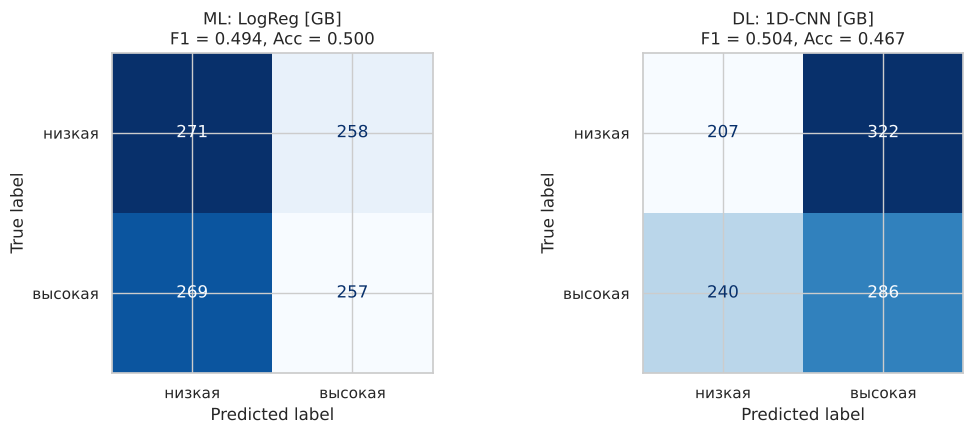

In [18]:
# Лучшие модели каждой группы и их матрицы ошибок
best = {f: clf_res[clf_res.family == f].sort_values("F1", ascending=False).iloc[0] for f in ["ML", "DL"]}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (f, r) in zip(ax, best.items()):
    p = preds[("clf", r.model, r.combo)]
    ConfusionMatrixDisplay(confusion_matrix(y_clf, (p >= 0.5).astype(int)), display_labels=["низкая", "высокая"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{f}: {r.model} [{r.combo}]\nF1 = {r.F1:.3f}, Acc = {r.Accuracy:.3f}")
plt.tight_layout(); plt.show()

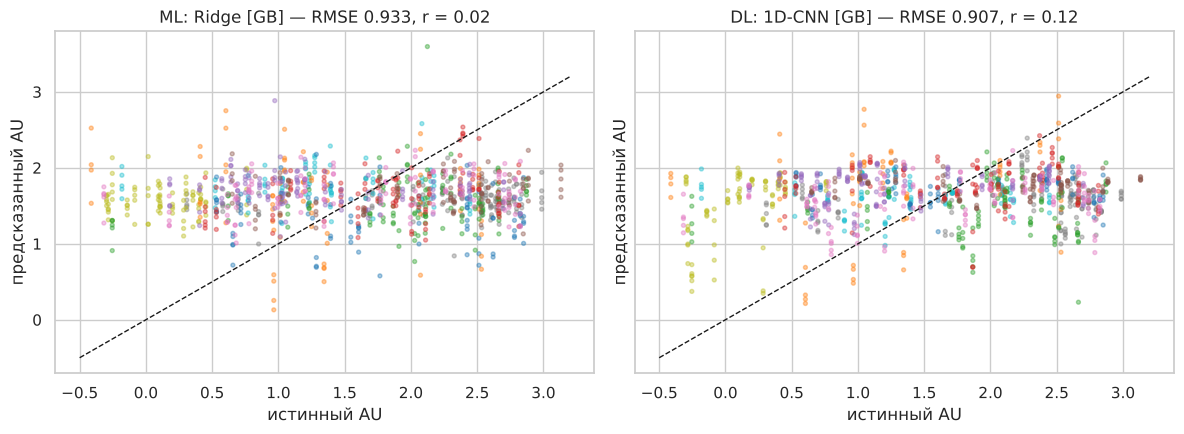

In [19]:
# Регрессия: предсказание против истины для лучших моделей
bestr = {f: reg_res[reg_res.family == f].sort_values("RMSE").iloc[0] for f in ["ML", "DL"]}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for a, (f, r) in zip(ax, bestr.items()):
    p = preds[("reg", r.model, r.combo)]
    a.scatter(y_reg, p, s=8, alpha=0.4, c=groups, cmap="tab10"); a.plot([-0.5, 3.2], [-0.5, 3.2], "k--", lw=1)
    a.set_title(f"{f}: {r.model} [{r.combo}] — RMSE {r.RMSE:.3f}, r = {r.Pearson:.2f}"); a.set_xlabel("истинный AU"); a.set_ylabel("предсказанный AU")
plt.tight_layout(); plt.show()

In [20]:
# Метрики по каждому тестовому участнику для лучшей ML-модели классификации
r = best["ML"]; p = preds[("clf", r.model, r.combo)]
per_subj = pd.DataFrame([dict(subject=s, n=(groups == s).sum(), share_high=y_clf[groups == s].mean(),
                              Accuracy=accuracy_score(y_clf[groups == s], p[groups == s] >= 0.5),
                              ROC_AUC=roc_auc_score(y_clf[groups == s], p[groups == s]) if y_clf[groups == s].std() > 0 else np.nan)
                         for s in np.unique(groups)])
per_subj.round(3)

,subject,n,share_high,Accuracy,ROC_AUC
0,3,92,0.489,0.446,0.478
1,4,74,0.270,0.432,0.450
2,5,120,0.792,0.450,0.632
3,6,117,0.650,0.581,0.592
4,7,125,0.240,0.432,0.584
5,8,95,0.684,0.621,0.696
6,9,125,0.520,0.528,0.574
7,10,135,0.778,0.452,0.604
8,11,87,0.000,0.724,NaN
9,12,85,0.294,0.353,0.478


In [21]:
# Агрегация на уровне сессии: усредняем предсказания 5 минут одной сессии (метка ведь одна на сессию)
sess_rows = []
for (task, model, combo), p in preds.items():
    d = pd.DataFrame({"session": meta.session, "p": p, "y": y_clf if task == "clf" else y_reg}).groupby("session").mean()
    m = clf_metrics(d.y.round().astype(int).values, d.p.values) if task == "clf" else reg_metrics(d.y.values, d.p.values)
    sess_rows.append(dict(task=task, model=model, combo=combo, **m))
sess_res = pd.DataFrame(sess_rows)
print("Уровень сессии (211 сессий) — лучшие конфигурации:")
display(sess_res[sess_res.task == "clf"].sort_values("F1", ascending=False).head(5)[["model", "combo", "Accuracy", "F1", "ROC_AUC"]].round(3))
display(sess_res[sess_res.task == "reg"].sort_values("RMSE").head(5)[["model", "combo", "RMSE", "MAE", "Pearson"]].round(3))

Уровень сессии (211 сессий) — лучшие конфигурации:


,model,combo,Accuracy,F1,ROC_AUC
80,LogReg,GB,0.517,0.519,0.512
141,Transformer,GB,0.441,0.487,0.401
137,1D-CNN,GB,0.450,0.482,0.452
38,LightGBM,B,0.483,0.478,0.433
145,CNN+LSTM,RGB,0.450,0.473,0.436


,model,combo,RMSE,MAE,Pearson
172,1D-CNN,GB,0.894,0.760,0.131
88,Ridge,GB,0.908,0.782,0.024
176,Transformer,GB,0.918,0.793,-0.055
40,Ridge,B,0.921,0.802,-0.164
173,LSTM,GB,0.922,0.797,-0.277


## 8. Почему результат около случайного: анализ схем валидации

Проверим одни и те же признаки (RGB, 90 шт.) и модели при трёх способах разбиения:

1. **Случайный KFold по минутам** — минуты одной сессии попадают и в train, и в test (**утечка**).
2. **GroupKFold по сессиям** — новые сессии уже знакомых участников (персонализированный сценарий).
3. **LOSO** — новые участники (основная схема).

In [22]:
Xrgb = F.values
schemes = {
    "1. Случайный KFold (утечка)": list(KFold(5, shuffle=True, random_state=SEED).split(Xrgb)),
    "2. GroupKFold по сессиям": list(GroupKFold(5).split(Xrgb, y_clf, meta.session.values)),
    "3. LOSO (новые люди)": list(logo.split(Xrgb, y_clf, groups)),
}
rows = []
for mname in ["LogReg", "RandomForest", "LightGBM"]:
    for sname, splits in schemes.items():
        p = np.zeros(len(y_clf))
        for tr, te in splits:
            m = CLF[mname](); m.fit(Xrgb[tr], y_clf[tr]); p[te] = m.predict_proba(Xrgb[te])[:, 1]
        rows.append(dict(model=mname, scheme=sname, **clf_metrics(y_clf, p)))
leak = pd.DataFrame(rows)
display(leak.pivot(index="model", columns="scheme", values="ROC_AUC").round(3))
display(leak.pivot(index="model", columns="scheme", values="Accuracy").round(3))

scheme,1. Случайный KFold (утечка),2. GroupKFold по сессиям,3. LOSO (новые люди)
model,,,
LightGBM,0.737,0.520,0.423
LogReg,0.592,0.550,0.475
RandomForest,0.691,0.516,0.418


scheme,1. Случайный KFold (утечка),2. GroupKFold по сессиям,3. LOSO (новые люди)
model,,,
LightGBM,0.680,0.524,0.456
LogReg,0.572,0.517,0.466
RandomForest,0.648,0.517,0.452


При случайном разбиении деревья дают ROC-AUC около 0,7 и выше. Это не настоящая точность: минуты одной сессии похожи друг на друга (одно освещение, одна поза) и имеют одну и ту же метку, поэтому модель «узнаёт сессию». Как только сессии или участники разводятся по train и test, качество падает до уровня случайного угадывания.

### 8.1. Перестановочный тест: как выглядит «случайно» при LOSO

Перемешиваем значения AU между сессиями **внутри каждого участника** (связь сигнала с меткой разрушается, а уровни участников сохраняются) и 50 раз заново прогоняем LOSO с логистической регрессией. Получается распределение метрик модели, которая заведомо ничего не знает.

,ROC_AUC,F1,Accuracy
mean,0.461,0.469,0.472
std,0.042,0.034,0.031
min,0.349,0.369,0.387
max,0.561,0.544,0.546


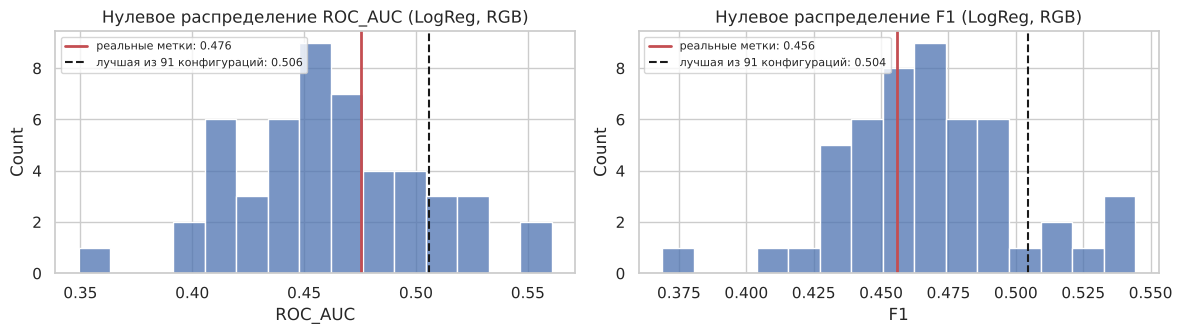

p-value (ROC-AUC реальной модели >= перестановочного): 0.3333333333333333


In [23]:
rng = np.random.default_rng(SEED)
sess_codes = meta.session.values
null = []
for it in range(50):
    y_perm = y_reg.copy()
    for s in subj_list:
        ss = np.unique(sess_codes[groups == s]); au = meta.groupby("session").AU.first()[ss].values
        mp = dict(zip(ss, rng.permutation(au)))
        idx = np.where(groups == s)[0]; y_perm[idx] = [mp[k] for k in sess_codes[idx]]
    yc = (y_perm > THR).astype(int); p = np.zeros(len(yc))
    for tr, te in logo.split(Xrgb, yc, groups):
        m = CLF["LogReg"](); m.fit(Xrgb[tr], yc[tr]); p[te] = m.predict_proba(Xrgb[te])[:, 1]
    null.append(dict(ROC_AUC=roc_auc_score(yc, p), F1=f1_score(yc, p >= 0.5), Accuracy=accuracy_score(yc, p >= 0.5)))
null = pd.DataFrame(null)
display(null.describe().loc[["mean", "std", "min", "max"]].round(3))
real = clf_res.query("model == 'LogReg' and combo == 'RGB'").iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, k in zip(ax, ["ROC_AUC", "F1"]):
    sns.histplot(null[k], ax=a, bins=15); a.axvline(real[k], c="r", lw=2, label=f"реальные метки: {real[k]:.3f}")
    a.axvline(clf_res[k].max(), c="k", ls="--", label=f"лучшая из {len(clf_res)} конфигураций: {clf_res[k].max():.3f}"); a.legend(fontsize=8); a.set_title(f"Нулевое распределение {k} (LogReg, RGB)")
plt.tight_layout(); plt.show()
print("p-value (ROC-AUC реальной модели >= перестановочного):", ((null.ROC_AUC >= real.ROC_AUC).sum() + 1) / (len(null) + 1))

## 9. Важность признаков (LightGBM, RGB)

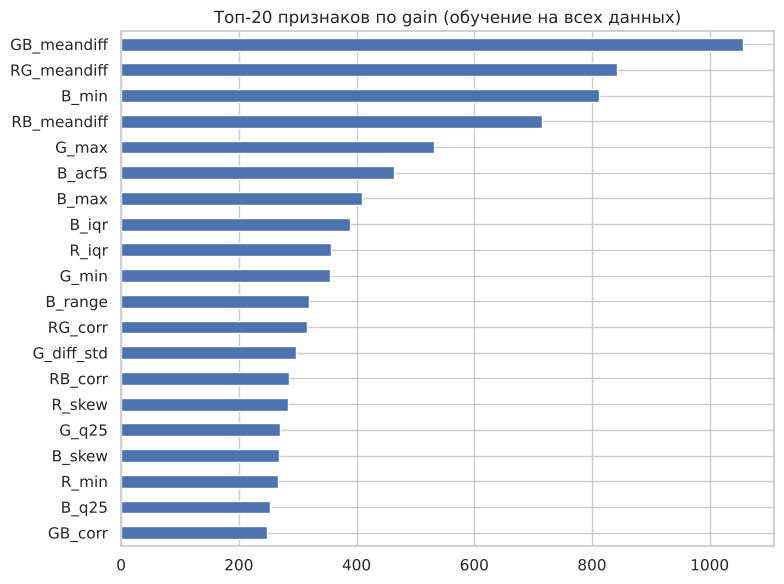

In [24]:
m = CLF["LightGBM"](); m.fit(F.values, y_clf)
imp = pd.Series(m.booster_.feature_importance("gain"), index=F.columns).sort_values(ascending=False)
imp.head(20)[::-1].plot.barh(figsize=(8, 6), title="Топ-20 признаков по gain (обучение на всех данных)"); plt.tight_layout(); plt.show()

Модель активно использует признаки (уровень сигнала, спектральные доли, автокорреляции), но, судя по LOSO, эти зависимости не переносятся на новых людей и новые сессии: модель подгоняется под особенности конкретных записей.

## 10. Итоговая таблица

In [25]:
summary_tbl = pd.concat([
    clf_res.sort_values("F1", ascending=False).groupby("family").head(3),
]).round(3)[["family", "model", "combo", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]]
display(summary_tbl)
display(reg_res.sort_values("RMSE").groupby("family").head(3).round(3)[["family", "model", "combo", "RMSE", "MAE", "R2", "Pearson"]])
display(baselines.round(3))
res.round(4).to_csv("results/all_results.csv", index=False)

,family,model,combo,Accuracy,Precision,Recall,F1,ROC_AUC
137,DL,1D-CNN,GB,0.467,0.470,0.544,0.504,0.459
145,DL,CNN+LSTM,RGB,0.477,0.477,0.521,0.498,0.450
140,DL,CNN+LSTM,GB,0.473,0.474,0.519,0.495,0.454
80,ML,LogReg,GB,0.500,0.499,0.489,0.494,0.506
83,ML,RandomForest,GB,0.482,0.481,0.490,0.486,0.447
38,ML,LightGBM,B,0.482,0.481,0.487,0.484,0.449


,family,model,combo,RMSE,MAE,R2,Pearson
172,DL,1D-CNN,GB,0.907,0.769,-0.044,0.125
173,DL,LSTM,GB,0.926,0.799,-0.087,-0.245
154,DL,GRU,G,0.928,0.808,-0.093,-0.251
88,ML,Ridge,GB,0.933,0.803,-0.104,0.021
40,ML,Ridge,B,0.938,0.813,-0.116,-0.106
8,ML,Ridge,R,0.939,0.813,-0.118,-0.158


,task,model,Accuracy,F1,ROC_AUC,RMSE,MAE,R2,Pearson
0,clf,Majority class,0.501,NaN,0.5,NaN,NaN,NaN,NaN
1,reg,Mean of train,NaN,NaN,NaN,0.922,0.802,-0.08,-0.593


## 11. Выводы

**1. Основной результат.** При честной проверке на новых людях (LOSO) ни одна из 91 конфигурации классификации (8 ML + 5 DL моделей × 7 комбинаций каналов) и ни одна из 91 конфигурации регрессии не предсказывает работоспособность заметно лучше случайного угадывания.
- Классификация: лучший F1 = 0,504 (1D-CNN, GB), лучший ROC-AUC = 0,506 (LogReg, GB) при бейзлайне 0,50. Метрики реальной модели (LogReg, RGB) неотличимы от модели, обученной на перемешанных метках (перестановочный тест, p ≈ 0,33).
- Регрессия: лучший RMSE = 0,907 (1D-CNN, GB) против 0,922 у предсказания среднего, то есть улучшение ~1,6 %. На уровне сессий 0,894. Для лучшей из 91 конфигурации это укладывается в разброс, R² везде отрицательный.

**2. Лучшая модель (формально).** Если выбирать по метрикам:
- для классификации — **логистическая регрессия на каналах G+B**. Accuracy 0,500, F1 0,494, ROC-AUC 0,506, лучший средний AUC внутри участника 0,565, на уровне сессий F1 0,519. Она самая простая и наименее переобученная.
- для регрессии — **1D-CNN на каналах G+B** (RMSE 0,907, MAE 0,769).

Это выбор «наименее плохой», а не работающей модели.

**3. Каналы.** Пара **G+B** лучшая в среднем по всем моделям (средний F1 0,448 против 0,38–0,42 у остальных; лучший RMSE). Это согласуется с литературой по rPPG: зелёный канал несёт больше всего информации о кровотоке. Но абсолютные различия малы, и при общем уровне «около случайного» делать уверенные выводы о каналах нельзя. Добавление R не помогает.

**4. ML vs DL.** В классификации ML в среднем немного лучше (средний F1 0,43 против 0,37). Рекуррентные сети (LSTM, GRU) хуже всех: ROC-AUC 0,27–0,36, они почти не используют сигнал и выдают «априорный» уровень обучающей выборки. В регрессии лучшие значения у DL, но разница в сотых. Для ~1000 минут и ~200 независимых меток сложные нейросети не дают преимущества.

**5. Почему метрики ниже 0,5.** Это не баг, а свойство LOSO при разном уровне AU у участников. Модель без информации предсказывает средний уровень обучающих участников, а он смещён в сторону, противоположную тестовому участнику. Подтверждения:
- предсказание среднего train-выборки имеет корреляцию с истинным AU **−0,59**;
- перестановочный тест даёт «случайный» ROC-AUC в среднем 0,46, а не 0,50.

Поэтому в работе отдельно приведены метрики внутри участника.

**6. Утечка данных.** При случайном разбиении минут те же модели дают ROC-AUC до 0,74 (LightGBM), Accuracy 0,68. Это результат утечки: метка ставится на сессию (~5 одинаковых минут), и модель «узнаёт» сессию по освещению и позе. При разбиении по сессиям AUC падает до 0,52–0,55, по участникам — до 0,42–0,48. Высокие цифры в подобных задачах почти всегда объясняются таким разбиением.

**7. Ограничения и что можно улучшить.**
- Частота 1 Гц: пульс и его вариабельность (главные физиологические маркеры усталости) из такого сигнала не извлекаются. Нужны исходные видео с частотой ≥ 25 кадров/с и rPPG-методы (CHROM, POS).
- Мало данных: 10 участников, 211 независимых меток. Сильная межиндивидуальная разница (участник 11).
- Метка одна на сессию, а признаки — поминутные. Более корректно агрегировать сигнал по всей сессии.
- Возможные улучшения: персонализированные модели (калибровка на нескольких сессиях человека), учёт времени суток, мультимодальность (поза, моргание, движения глаз).